# XStore Benchmarks – Big Experiments

## Libraries

In [1]:
from fabric import ThreadingGroup, Connection
from chi import server, ssh
import os
import warnings
import time
import sys
sys.path.append('../scripts')
from utilities import *
warnings.filterwarnings('ignore')

## Configurations

In [2]:
sshUser = "ubuntu"
server_ips = ["64.131.114.155"]
server_local_ips = {}
client_ips = ["64.131.114.143", "64.131.114.145", "64.131.114.146", "64.131.114.147",
              "64.131.114.148", "64.131.114.152", "64.131.114.153", "64.131.114.154"]

storageType = {"HDD": "/HDD", "NVME": "/NVME_RAID-0"}
SERVER_WORKING_DIR = storageType["NVME"]

## Initialize environment

In [3]:
# These groups are for processing in parallel 
serverConnections = [makeConnection(i, user=sshUser) for i in server_ips]
clientConnections = [makeConnection(i, user=sshUser) for i in client_ips]
allConnections = (serverConnections + clientConnections)
serverGroup = ThreadingGroup.from_connections(serverConnections)
clientGroup = ThreadingGroup.from_connections(clientConnections)
allGroup = ThreadingGroup.from_connections(allConnections)

# Get local IP for server
local_ips = serverGroup.run("hostname -I | cut -d ' ' -f 1", hide=True)
for i in local_ips:
    server_local_ips[i.host] = local_ips[i].stdout.strip()

# Update & Upgrade latest packages
allGroup.run("sudo apt update && sudo apt upgrade -y", hide=True)
rebootGroup(allGroup)

Wait for all server to come online after reboot

In [4]:
# Buffer of reboot (no more +1 min shutdown-schedule delay)
time.sleep(240)

for ip in (server_ips + client_ips):
    waitForSSH(ip, user=sshUser, timeout=1200)

## Datasets

Preparing test datasets on client nodes

In [5]:
clientGroup.put("../scripts/initData.sh")
clientGroup.run("bash initData.sh MYSTIC@IIT", hide=True);

## Benchmark server (XStore)

Prepare benchmark server

In [6]:
serverGroup.put("../scripts/_common.sh")
serverGroup.put("../scripts/XStore/initXStoreServer.sh")
serverGroup.run(f"sudo chmod -R 777 {SERVER_WORKING_DIR}; bash initXStoreServer.sh {SERVER_WORKING_DIR}", hide=True);

## Benchmark client (XBench)
Prepare benchmark client

In [7]:
clientGroup.put("../scripts/initXBenchClient.sh")
clientGroup.run("bash initXBenchClient.sh", hide=True)
clientGroup.close()

## Experiments - Settings

In [8]:
targetThreads = [1, 2, 4, 8, 16, 32, 64]
numClients = [i * len(client_ips) for i in targetThreads]

## Experiment – UNARY INSERT (SEQ)
**Perform experiments**

In [9]:
runWorkload("INSERT_UNARY_SEQ", targetThreads, server_local_ips[server_ips[0]], 9497, "XStore", client_ips, 1000, 0, serverGroup, SERVER_WORKING_DIR, "ubuntu")

[Benchmark Config]
  Target Clients     : 1
  Total Machines     : 8
  Machines Used      : 1
  Threads per Machine: 1
  Total Clients Actual : 1
[Benchmark: 1] - Schedule workload on 1786930287
[Benchmark: 1] [Client: 64.131.114.143] - Time now: 1786930177 | Delta: 110
[Benchmark: 1] [Client: 64.131.114.143] - Downloaded 1 result files
[Benchmark: 1] [Server] - Downloaded system stats files
[Benchmark Config]
  Target Clients     : 2
  Total Machines     : 8
  Machines Used      : 1
  Threads per Machine: 2
  Total Clients Actual : 2
[Benchmark: 2] - Schedule workload on 1786930520
[Benchmark: 2] [Client: 64.131.114.143] - Time now: 1786930407 | Delta: 113
[Benchmark: 2] [Client: 64.131.114.143] - Downloaded 2 result files
[Benchmark: 2] [Server] - Downloaded system stats files
[Benchmark Config]
  Target Clients     : 4
  Total Machines     : 8
  Machines Used      : 1
  Threads per Machine: 4
  Total Clients Actual : 4
[Benchmark: 4] - Schedule workload on 1786930765
[Benchmark: 4] 

**Visualization**

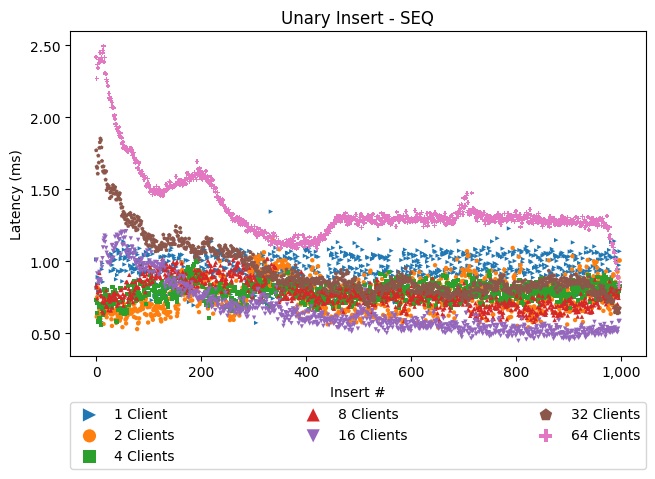

In [10]:
unaryPlots("INSERT_UNARY_SEQ", "XStore", targetThreads, client_ips, "Insert")

## Experiment – UNARY INSERT (RAND)
**Perform experiments**

In [11]:
runWorkload("INSERT_UNARY_RAND", targetThreads, server_local_ips[server_ips[0]], 9497, "XStore", client_ips, 1000, 0, serverGroup, SERVER_WORKING_DIR, "ubuntu")

[Benchmark Config]
  Target Clients     : 1
  Total Machines     : 8
  Machines Used      : 1
  Threads per Machine: 1
  Total Clients Actual : 1
[Benchmark: 1] - Schedule workload on 1786940695
[Benchmark: 1] [Client: 64.131.114.143] - Time now: 1786940583 | Delta: 112
[Benchmark: 1] [Client: 64.131.114.143] - Downloaded 1 result files
[Benchmark: 1] [Server] - Downloaded system stats files
[Benchmark Config]
  Target Clients     : 2
  Total Machines     : 8
  Machines Used      : 1
  Threads per Machine: 2
  Total Clients Actual : 2
[Benchmark: 2] - Schedule workload on 1786940927
[Benchmark: 2] [Client: 64.131.114.143] - Time now: 1786940814 | Delta: 113
[Benchmark: 2] [Client: 64.131.114.143] - Downloaded 2 result files
[Benchmark: 2] [Server] - Downloaded system stats files
[Benchmark Config]
  Target Clients     : 4
  Total Machines     : 8
  Machines Used      : 1
  Threads per Machine: 4
  Total Clients Actual : 4
[Benchmark: 4] - Schedule workload on 1786941160
[Benchmark: 4] 

**Visualization**

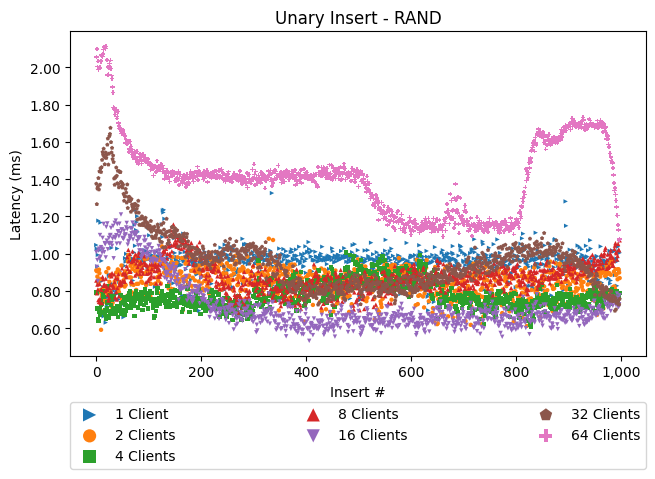

In [12]:
unaryPlots("INSERT_UNARY_RAND", "XStore", targetThreads, client_ips, "Insert")

## Experiment – BATCH INSERT (SEQ)
**Perform experiments**

In [13]:
runWorkload("INSERT_BATCH_SEQ", targetThreads, server_local_ips[server_ips[0]], 9497, "XStore", client_ips, 1000, 10, serverGroup, SERVER_WORKING_DIR, "ubuntu")

[Benchmark Config]
  Target Clients     : 1
  Total Machines     : 8
  Machines Used      : 1
  Threads per Machine: 1
  Total Clients Actual : 1
[Benchmark: 1] - Schedule workload on 1786934810
[Benchmark: 1] [Client: 64.131.114.143] - Time now: 1786934698 | Delta: 112
[Benchmark: 1] [Client: 64.131.114.143] - Downloaded 1 result files
[Benchmark: 1] [Server] - Downloaded system stats files
[Benchmark Config]
  Target Clients     : 2
  Total Machines     : 8
  Machines Used      : 1
  Threads per Machine: 2
  Total Clients Actual : 2
[Benchmark: 2] - Schedule workload on 1786935043
[Benchmark: 2] [Client: 64.131.114.143] - Time now: 1786934931 | Delta: 112
[Benchmark: 2] [Client: 64.131.114.143] - Downloaded 2 result files
[Benchmark: 2] [Server] - Downloaded system stats files
[Benchmark Config]
  Target Clients     : 4
  Total Machines     : 8
  Machines Used      : 1
  Threads per Machine: 4
  Total Clients Actual : 4
[Benchmark: 4] - Schedule workload on 1786935277
[Benchmark: 4] 

**Visualization**

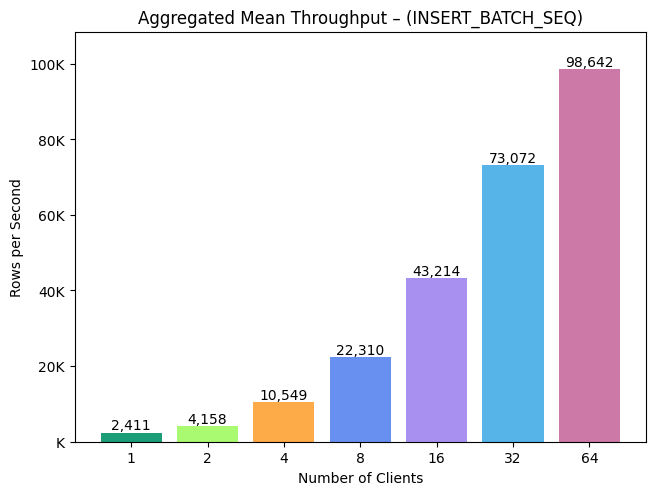

In [14]:
batchPlots("INSERT_BATCH_SEQ", "XStore", targetThreads, client_ips)

## Experiment – BATCH INSERT (RAND)
**Perform experiments**

In [15]:
runWorkload("INSERT_BATCH_RAND", targetThreads, server_local_ips[server_ips[0]], 9497, "XStore", client_ips, 1000, 10, serverGroup, SERVER_WORKING_DIR, "ubuntu")

[Benchmark Config]
  Target Clients     : 1
  Total Machines     : 8
  Machines Used      : 1
  Threads per Machine: 1
  Total Clients Actual : 1
[Benchmark: 1] - Schedule workload on 1786937062
[Benchmark: 1] [Client: 64.131.114.143] - Time now: 1786936950 | Delta: 112
[Benchmark: 1] [Client: 64.131.114.143] - Downloaded 1 result files
[Benchmark: 1] [Server] - Downloaded system stats files
[Benchmark Config]
  Target Clients     : 2
  Total Machines     : 8
  Machines Used      : 1
  Threads per Machine: 2
  Total Clients Actual : 2
[Benchmark: 2] - Schedule workload on 1786937295
[Benchmark: 2] [Client: 64.131.114.143] - Time now: 1786937183 | Delta: 112
[Benchmark: 2] [Client: 64.131.114.143] - Downloaded 2 result files
[Benchmark: 2] [Server] - Downloaded system stats files
[Benchmark Config]
  Target Clients     : 4
  Total Machines     : 8
  Machines Used      : 1
  Threads per Machine: 4
  Total Clients Actual : 4
[Benchmark: 4] - Schedule workload on 1786937529
[Benchmark: 4] 

**Visualization**

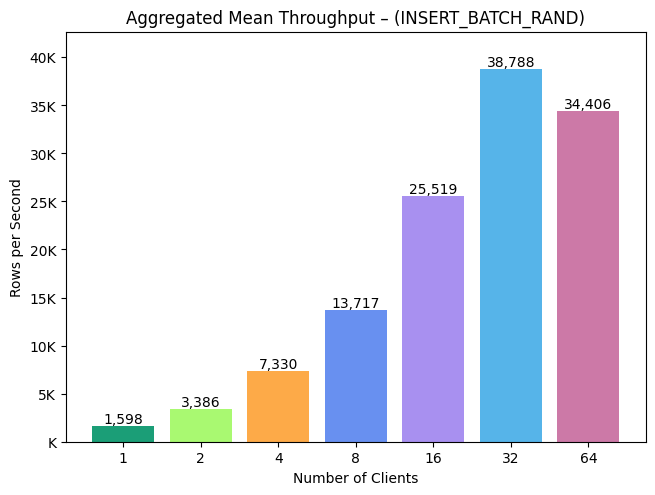

In [16]:
batchPlots("INSERT_BATCH_RAND", "XStore", targetThreads, client_ips)

## Bootstrap Database

Reboot server to a fresh state to avoid becoming non-accessible from public network

In [17]:
rebootGroup(allGroup)

# Buffer of reboot (no more +1 min shutdown-schedule delay)
time.sleep(240)

for ip in (server_ips + client_ips):
    waitForSSH(ip, user=sshUser, timeout=1200)

<div class="alert alert-block alert-info">Note: This is required so that there's actual data for clients to query from</div>

In [18]:
serverGroup.put("../scripts/restoreDB.sh")

# Restore DB
serverGroup.run(f"bash restoreDB.sh MYSTIC@IIT XStore BENCH_DB {SERVER_WORKING_DIR}", hide=True)

# Keep checking if job is done running in tmux window
checkTmuxJobIsDone(serverGroup);

## Experiment – UNARY QUERY (SEQ)

**Perform experiments**

In [19]:
runWorkload("QUERY_UNARY_SEQ", targetThreads, server_local_ips[server_ips[0]], 9497, "XStore", client_ips, 1000, 0, serverGroup, SERVER_WORKING_DIR, "ubuntu")

[Benchmark Config]
  Target Clients     : 1
  Total Machines     : 8
  Machines Used      : 1
  Threads per Machine: 1
  Total Clients Actual : 1
[Benchmark: 1] - Schedule workload on 1786945270
[Benchmark: 1] [Client: 64.131.114.143] - Time now: 1786945158 | Delta: 112
[Benchmark: 1] [Client: 64.131.114.143] - Downloaded 1 result files
[Benchmark: 1] [Server] - Downloaded system stats files
[Benchmark Config]
  Target Clients     : 2
  Total Machines     : 8
  Machines Used      : 1
  Threads per Machine: 2
  Total Clients Actual : 2
[Benchmark: 2] - Schedule workload on 1786945502
[Benchmark: 2] [Client: 64.131.114.143] - Time now: 1786945389 | Delta: 113
[Benchmark: 2] [Client: 64.131.114.143] - Downloaded 2 result files
[Benchmark: 2] [Server] - Downloaded system stats files
[Benchmark Config]
  Target Clients     : 4
  Total Machines     : 8
  Machines Used      : 1
  Threads per Machine: 4
  Total Clients Actual : 4
[Benchmark: 4] - Schedule workload on 1786945736
[Benchmark: 4] 

**Visualization**

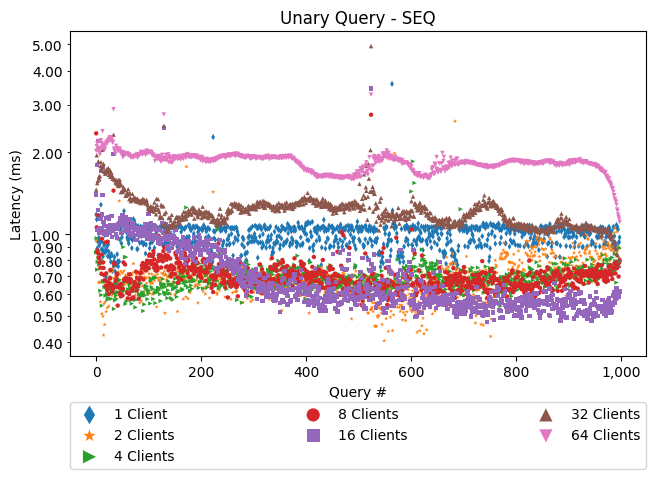

In [20]:
unaryPlots("QUERY_UNARY_SEQ", "XStore", targetThreads, client_ips, "Query", logScale=True)

## Experiment – UNARY QUERY (RAND)

**Perform experiments**

In [21]:
runWorkload("QUERY_UNARY_RAND", targetThreads, server_local_ips[server_ips[0]], 9497, "XStore", client_ips, 1000, 0, serverGroup, SERVER_WORKING_DIR, "ubuntu")

[Benchmark Config]
  Target Clients     : 1
  Total Machines     : 8
  Machines Used      : 1
  Threads per Machine: 1
  Total Clients Actual : 1
[Benchmark: 1] - Schedule workload on 1786947513
[Benchmark: 1] [Client: 64.131.114.143] - Time now: 1786947400 | Delta: 113
[Benchmark: 1] [Client: 64.131.114.143] - Downloaded 1 result files
[Benchmark: 1] [Server] - Downloaded system stats files
[Benchmark Config]
  Target Clients     : 2
  Total Machines     : 8
  Machines Used      : 1
  Threads per Machine: 2
  Total Clients Actual : 2
[Benchmark: 2] - Schedule workload on 1786947746
[Benchmark: 2] [Client: 64.131.114.143] - Time now: 1786947633 | Delta: 113
[Benchmark: 2] [Client: 64.131.114.143] - Downloaded 2 result files
[Benchmark: 2] [Server] - Downloaded system stats files
[Benchmark Config]
  Target Clients     : 4
  Total Machines     : 8
  Machines Used      : 1
  Threads per Machine: 4
  Total Clients Actual : 4
[Benchmark: 4] - Schedule workload on 1786947980
[Benchmark: 4] 

**Visualization**

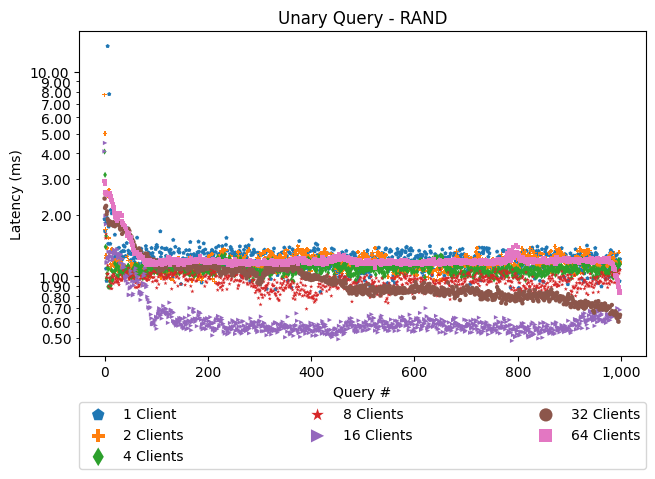

In [22]:
unaryPlots("QUERY_UNARY_RAND", "XStore", targetThreads, client_ips, "Query", logScale=True)

## Experiment – BATCH QUERY (SEQ)

**Perform experiments**

In [23]:
runWorkload("QUERY_BATCH_SEQ", targetThreads, server_local_ips[server_ips[0]], 9497, "XStore", client_ips, 100, 10, serverGroup, SERVER_WORKING_DIR, "ubuntu")

[Benchmark Config]
  Target Clients     : 1
  Total Machines     : 8
  Machines Used      : 1
  Threads per Machine: 1
  Total Clients Actual : 1
[Benchmark: 1] - Schedule workload on 1786949758
[Benchmark: 1] [Client: 64.131.114.143] - Time now: 1786949645 | Delta: 113
[Benchmark: 1] [Client: 64.131.114.143] - Downloaded 1 result files
[Benchmark: 1] [Server] - Downloaded system stats files
[Benchmark Config]
  Target Clients     : 2
  Total Machines     : 8
  Machines Used      : 1
  Threads per Machine: 2
  Total Clients Actual : 2
[Benchmark: 2] - Schedule workload on 1786949996
[Benchmark: 2] [Client: 64.131.114.143] - Time now: 1786949882 | Delta: 114
[Benchmark: 2] [Client: 64.131.114.143] - Downloaded 2 result files
[Benchmark: 2] [Server] - Downloaded system stats files
[Benchmark Config]
  Target Clients     : 4
  Total Machines     : 8
  Machines Used      : 1
  Threads per Machine: 4
  Total Clients Actual : 4
[Benchmark: 4] - Schedule workload on 1786950230
[Benchmark: 4] 

**Visualization**

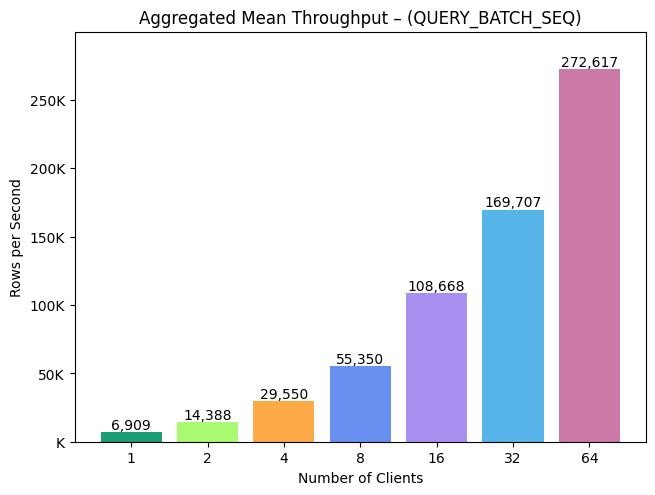

In [24]:
batchPlots("QUERY_BATCH_SEQ", "XStore", targetThreads, client_ips, 100)

## Experiment – BATCH QUERY (RAND)

**Perform experiments**

In [25]:
runWorkload("QUERY_BATCH_RAND", targetThreads, server_local_ips[server_ips[0]], 9497, "XStore", client_ips, 100, 10, serverGroup, SERVER_WORKING_DIR, "ubuntu")

[Benchmark Config]
  Target Clients     : 1
  Total Machines     : 8
  Machines Used      : 1
  Threads per Machine: 1
  Total Clients Actual : 1
[Benchmark: 1] - Schedule workload on 1786952001
[Benchmark: 1] [Client: 64.131.114.143] - Time now: 1786951888 | Delta: 113
[Benchmark: 1] [Client: 64.131.114.143] - Downloaded 1 result files
[Benchmark: 1] [Server] - Downloaded system stats files
[Benchmark Config]
  Target Clients     : 2
  Total Machines     : 8
  Machines Used      : 1
  Threads per Machine: 2
  Total Clients Actual : 2
[Benchmark: 2] - Schedule workload on 1786952233
[Benchmark: 2] [Client: 64.131.114.143] - Time now: 1786952120 | Delta: 113
[Benchmark: 2] [Client: 64.131.114.143] - Downloaded 2 result files
[Benchmark: 2] [Server] - Downloaded system stats files
[Benchmark Config]
  Target Clients     : 4
  Total Machines     : 8
  Machines Used      : 1
  Threads per Machine: 4
  Total Clients Actual : 4
[Benchmark: 4] - Schedule workload on 1786952466
[Benchmark: 4] 

**Visualization**

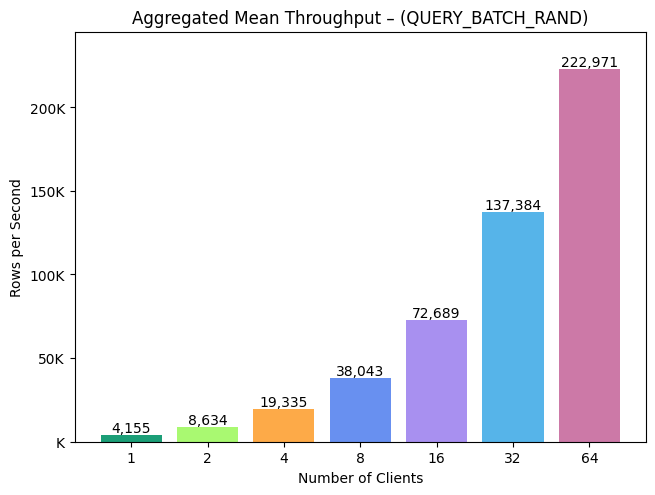

In [26]:
batchPlots("QUERY_BATCH_RAND", "XStore", targetThreads, client_ips, 100)

## Refresh Database

Reboot server to a fresh state to avoid becoming non-accessible from public network

In [27]:
rebootGroup(allGroup)

# Buffer of reboot (no more +1 min shutdown-schedule delay)
time.sleep(240)

for ip in (server_ips + client_ips):
    waitForSSH(ip, user=sshUser, timeout=1200)

## Experiment – MIN AGG QUERY

**Perform experiments**

In [28]:
runWorkload("AGG_MIN_QUERY", targetThreads, server_local_ips[server_ips[0]], 9497, "XStore", client_ips, 60, 1000, serverGroup, SERVER_WORKING_DIR, "ubuntu")

[Benchmark Config]
  Target Clients     : 1
  Total Machines     : 8
  Machines Used      : 1
  Threads per Machine: 1
  Total Clients Actual : 1
[Benchmark: 1] - Schedule workload on 1786969385
[Benchmark: 1] [Client: 64.131.114.143] - Time now: 1786969273 | Delta: 112
[Benchmark: 1] [Client: 64.131.114.143] - Downloaded 1 result files
[Benchmark: 1] [Server] - Downloaded system stats files
[Benchmark Config]
  Target Clients     : 2
  Total Machines     : 8
  Machines Used      : 1
  Threads per Machine: 2
  Total Clients Actual : 2
[Benchmark: 2] - Schedule workload on 1786969618
[Benchmark: 2] [Client: 64.131.114.143] - Time now: 1786969505 | Delta: 113
[Benchmark: 2] [Client: 64.131.114.143] - Downloaded 2 result files
[Benchmark: 2] [Server] - Downloaded system stats files
[Benchmark Config]
  Target Clients     : 4
  Total Machines     : 8
  Machines Used      : 1
  Threads per Machine: 4
  Total Clients Actual : 4
[Benchmark: 4] - Schedule workload on 1786969851
[Benchmark: 4] 

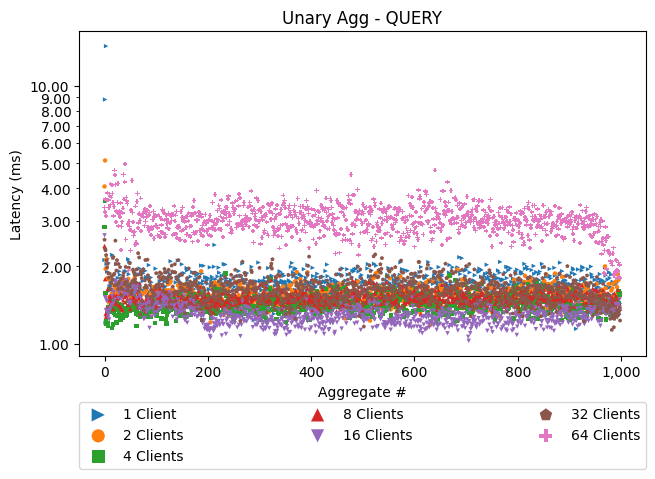

In [29]:
unaryPlots("AGG_MIN_QUERY", "XStore", targetThreads, client_ips, "Aggregate", logScale=True)

## Experiment – MAX AGG QUERY

**Perform experiments**

In [30]:
runWorkload("AGG_MAX_QUERY", targetThreads, server_local_ips[server_ips[0]], 9497, "XStore", client_ips, 60, 1000, serverGroup, SERVER_WORKING_DIR, "ubuntu")

[Benchmark Config]
  Target Clients     : 1
  Total Machines     : 8
  Machines Used      : 1
  Threads per Machine: 1
  Total Clients Actual : 1
[Benchmark: 1] - Schedule workload on 1786971620
[Benchmark: 1] [Client: 64.131.114.143] - Time now: 1786971507 | Delta: 113
[Benchmark: 1] [Client: 64.131.114.143] - Downloaded 1 result files
[Benchmark: 1] [Server] - Downloaded system stats files
[Benchmark Config]
  Target Clients     : 2
  Total Machines     : 8
  Machines Used      : 1
  Threads per Machine: 2
  Total Clients Actual : 2
[Benchmark: 2] - Schedule workload on 1786971853
[Benchmark: 2] [Client: 64.131.114.143] - Time now: 1786971740 | Delta: 113
[Benchmark: 2] [Client: 64.131.114.143] - Downloaded 2 result files
[Benchmark: 2] [Server] - Downloaded system stats files
[Benchmark Config]
  Target Clients     : 4
  Total Machines     : 8
  Machines Used      : 1
  Threads per Machine: 4
  Total Clients Actual : 4
[Benchmark: 4] - Schedule workload on 1786972086
[Benchmark: 4] 

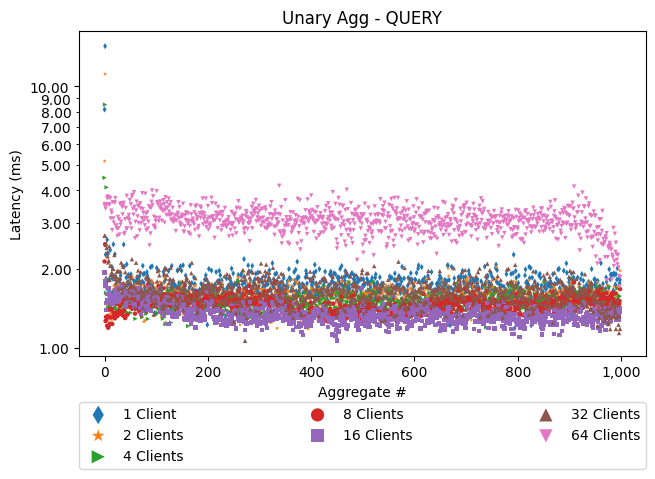

In [31]:
unaryPlots("AGG_MAX_QUERY", "XStore", targetThreads, client_ips, "Aggregate", logScale=True)

## Experiment – SUM AGG QUERY

**Perform experiments**

In [32]:
runWorkload("AGG_SUM_QUERY", targetThreads, server_local_ips[server_ips[0]], 9497, "XStore", client_ips, 60, 1000, serverGroup, SERVER_WORKING_DIR, "ubuntu")

[Benchmark Config]
  Target Clients     : 1
  Total Machines     : 8
  Machines Used      : 1
  Threads per Machine: 1
  Total Clients Actual : 1
[Benchmark: 1] - Schedule workload on 1786973858
[Benchmark: 1] [Client: 64.131.114.143] - Time now: 1786973745 | Delta: 113
[Benchmark: 1] [Client: 64.131.114.143] - Downloaded 1 result files
[Benchmark: 1] [Server] - Downloaded system stats files
[Benchmark Config]
  Target Clients     : 2
  Total Machines     : 8
  Machines Used      : 1
  Threads per Machine: 2
  Total Clients Actual : 2
[Benchmark: 2] - Schedule workload on 1786974091
[Benchmark: 2] [Client: 64.131.114.143] - Time now: 1786973978 | Delta: 113
[Benchmark: 2] [Client: 64.131.114.143] - Downloaded 2 result files
[Benchmark: 2] [Server] - Downloaded system stats files
[Benchmark Config]
  Target Clients     : 4
  Total Machines     : 8
  Machines Used      : 1
  Threads per Machine: 4
  Total Clients Actual : 4
[Benchmark: 4] - Schedule workload on 1786974324
[Benchmark: 4] 

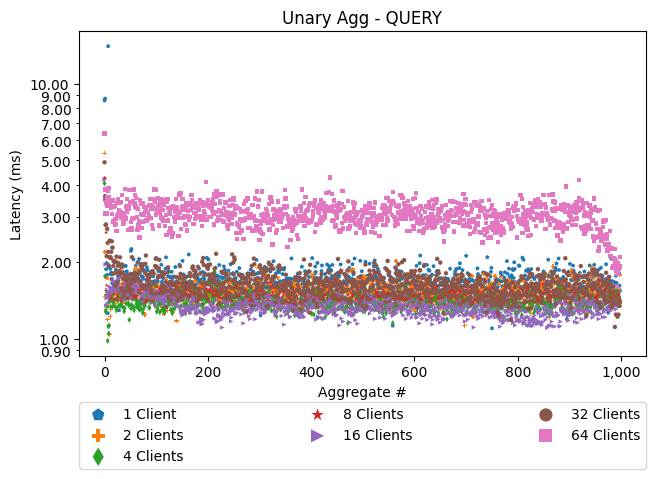

In [33]:
unaryPlots("AGG_SUM_QUERY", "XStore", targetThreads, client_ips, "Aggregate", logScale=True)

## Experiment – AVG AGG QUERY

**Perform experiments**

In [34]:
runWorkload("AGG_AVG_QUERY", targetThreads, server_local_ips[server_ips[0]], 9497, "XStore", client_ips, 60, 1000, serverGroup, SERVER_WORKING_DIR, "ubuntu")

[Benchmark Config]
  Target Clients     : 1
  Total Machines     : 8
  Machines Used      : 1
  Threads per Machine: 1
  Total Clients Actual : 1
[Benchmark: 1] - Schedule workload on 1786976101
[Benchmark: 1] [Client: 64.131.114.143] - Time now: 1786975988 | Delta: 113
[Benchmark: 1] [Client: 64.131.114.143] - Downloaded 1 result files
[Benchmark: 1] [Server] - Downloaded system stats files
[Benchmark Config]
  Target Clients     : 2
  Total Machines     : 8
  Machines Used      : 1
  Threads per Machine: 2
  Total Clients Actual : 2
[Benchmark: 2] - Schedule workload on 1786976335
[Benchmark: 2] [Client: 64.131.114.143] - Time now: 1786976221 | Delta: 114
[Benchmark: 2] [Client: 64.131.114.143] - Downloaded 2 result files
[Benchmark: 2] [Server] - Downloaded system stats files
[Benchmark Config]
  Target Clients     : 4
  Total Machines     : 8
  Machines Used      : 1
  Threads per Machine: 4
  Total Clients Actual : 4
[Benchmark: 4] - Schedule workload on 1786976574
[Benchmark: 4] 

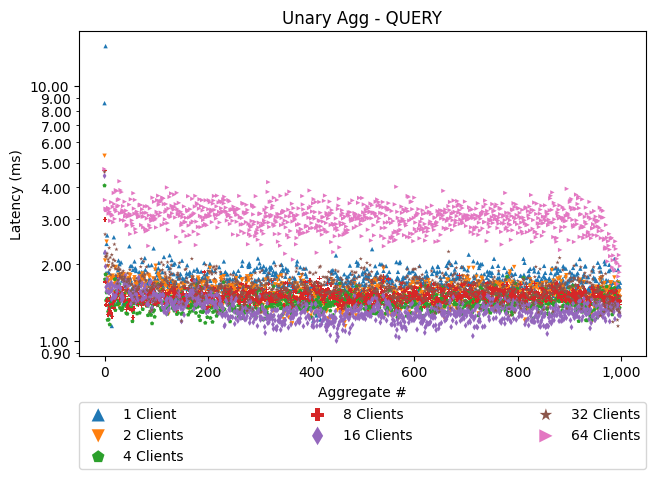

In [35]:
unaryPlots("AGG_AVG_QUERY", "XStore", targetThreads, client_ips, "Aggregate", logScale=True)